# **Previsão de Churn (Abandono) em Telecom (XGBoost)**


# 1. Importando bibliotecas

In [16]:
# 1. Instalação
!pip install optuna xgboost scikit-learn --upgrade --quiet

# 2. Imports
import pandas as pd
import numpy as np
import io
import optuna
import xgboost as xgb
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils import shuffle
from sklearn.metrics import (
    log_loss, mean_squared_error, confusion_matrix,
    roc_auc_score, recall_score, precision_score,
    f1_score, classification_report
)
from scipy.stats import ks_2samp
from google.colab import files

# 3. Configuração GPU
if torch.cuda.is_available():
    DEVICE = "cuda"
    TREE_METHOD = "hist"
    print("✅ GPU Ativada!")
else:
    DEVICE = "cpu"
    TREE_METHOD = "hist"
    print("⚠️ Rodando em CPU.")

✅ GPU Ativada!


## 2. Carregamento da Base de Dados


In [17]:
print("Por favor, faça o upload do ficheiro CSV:")
uploaded = files.upload()

# Carregamento automático do primeiro ficheiro enviado
file_name = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[file_name]))

print(f"\nFicheiro '{file_name}' carregado com sucesso!")
print(f"Dimensões: {data.shape}")
data.head()

Por favor, faça o upload do ficheiro CSV:


Saving customer_churn_telecom_services.csv to customer_churn_telecom_services (1).csv

Ficheiro 'customer_churn_telecom_services (1).csv' carregado com sucesso!
Dimensões: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 3. Dividindo dados

In [18]:
def separa_classe(df_class):
    df_class = shuffle(df_class, random_state=42)

    n = len(df_class)
    train = df_class.iloc[:int(0.5*n)]
    val   = df_class.iloc[int(0.5*n):int(0.75*n)]
    test  = df_class.iloc[int(0.75*n):]

    return train, val, test


def balanceamento(df_maior, df_menor):
    df_menor_bal = df_menor.sample(n=len(df_maior), replace=True, random_state=42)
    return df_menor_bal


def junta_e_mistura(df_x, df_y):
  return shuffle(pd.concat([df_x, df_y]), random_state=42)

In [19]:
# Separar classes
# Classe 1 = Churn no
# Classe 2 = Churn yes
data_cl1 = data[data["Churn"] == "No"]
data_cl2 = data[data["Churn"] == "Yes"]

# Para cada classe, separar treino(50%), validação(25%) e teste(25%) de cada classe
data_cl1_train, data_cl1_val, data_cl1_test = separa_classe(data_cl1)
data_cl2_train, data_cl2_val, data_cl2_test = separa_classe(data_cl2)

# Balancear os dados de treino e validação da classe 2 até ter mesma quantidade que os da classe 1
data_cl2_train = balanceamento(data_cl1_train, data_cl2_train)
data_cl2_val = balanceamento(data_cl1_val, data_cl2_val)


# Embaralhar dados de treino, validação e teste
data_train = junta_e_mistura(data_cl1_train, data_cl2_train)
data_val = junta_e_mistura(data_cl1_val, data_cl2_val)
data_test = junta_e_mistura(data_cl1_test, data_cl2_test)

In [20]:
print("Tamanhos finais:")
print("Treino:", data_train.shape)
print("Validação:", data_val.shape)
print("Teste:", data_test.shape)

Tamanhos finais:
Treino: (5174, 20)
Validação: (2586, 20)
Teste: (1762, 20)


# 4. Tratamento de dados

In [21]:
target = "Churn"

train_copy = data_train.copy()
val_copy = data_val.copy()
test_copy = data_test.copy()

#  Separa valores target de treino, validação e teste:
y_train = train_copy[target]
y_val   = val_copy[target]
y_test  = test_copy[target]

# Remover os valores target dos datasets para passar ao preprocessor:
tratando_train = train_copy.drop(columns=[target])
tratando_val = val_copy.drop(columns=[target])
tratando_test = test_copy.drop(columns=[target])

In [22]:
# ===============================
# Funções de pré-processamento
# ===============================

def treat_missing(df):
    num_cols = df.select_dtypes(include=['int64','float64']).columns
    cat_cols = df.select_dtypes(include=['object','category']).columns

    # Numéricos → mediana
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())

    # Categóricos → Missing
    df[cat_cols] = df[cat_cols].fillna("Missing")

    return df


def remove_outliers_iqr(df, cols):
    for c in cols:
        Q1 = df[c].quantile(0.25)
        Q3 = df[c].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df = df[(df[c] >= lower) & (df[c] <= upper)]
    return df


def fix_inconsistencies(df):
    # Converter TotalCharges para numérico
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
        df["TotalCharges"] = df["TotalCharges"].fillna(0)

    # Tenure não pode ser negativo
    if "tenure" in df.columns:
        df = df[df["tenure"] >= 0]

    return df


# ===============================
# Criação de variáveis agregadas
# ===============================

def create_features(df):
    df = df.copy()

    # Exemplo de feature: razão entre total e mensal
    if "TotalCharges" in df.columns and "MonthlyCharges" in df.columns:
        df["monthly_total_ratio"] = df["MonthlyCharges"] / (df["TotalCharges"] + 1)

    # Exemplo: binning do tenure
    if "tenure" in df.columns:
        df["tenure_bin"] = pd.cut(
            df["tenure"],
            bins=[0, 12, 24, 48, 100],
            labels=["0-12", "13-24", "25-48", "48+"]
        )

    return df

In [23]:
# 1. Missing
tratando_train = treat_missing(tratando_train)
tratando_val = treat_missing(tratando_val)
tratando_test = treat_missing(tratando_test)

# 2. Outliers (apenas treino)
num_cols_outliers = tratando_train.select_dtypes(include=['int64','float64']).columns
tratando_train = remove_outliers_iqr(tratando_train, num_cols_outliers)

# 3. Inconsistências
tratando_train = fix_inconsistencies(tratando_train)
tratando_val = fix_inconsistencies(tratando_val)
tratando_test = fix_inconsistencies(tratando_test)

# 4. Variáveis agregadas / transformações
tratando_train = create_features(tratando_train)
tratando_val = create_features(tratando_val)
tratando_test = create_features(tratando_test)

# 5. Normalização + Codificação
num_cols = tratando_train.select_dtypes(include=['int64','float64','float32']).columns
cat_cols = tratando_train.select_dtypes(include=['object','category']).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# Fit no treino (correto!)
preprocessor.fit(tratando_train)

# Transform no resto
X_train = preprocessor.transform(tratando_train)
X_val   = preprocessor.transform(tratando_val)
X_test  = preprocessor.transform(tratando_test)

# 5. Configuração e Sincronização
Nesta etapa, corrigimos o desalinhamento gerado na Célula 13 (onde removemos outliers do X, mas o y ficou intacto). Usamos os índices para filtrar o y e garantir que os tamanhos batam.

In [24]:
# ==============================================================================
# 5. Correção de Alinhamento e Features (Sincronização Final)
# ==============================================================================

# 1. Instalar bibliotecas
!pip install optuna xgboost --quiet

import xgboost as xgb
import optuna
import torch
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

print("=== Corrigindo Desalinhamento e Features ===")

# PASSO 1: Pegar o dataframe de treino completo original (Célula 11)
df_fix = train_copy.copy()

print(f"Tamanho Inicial: {df_fix.shape[0]}")

# PASSO 2: Recriar as Features EXATAMENTE como na Célula 12
# Isso é obrigatório porque o preprocessor espera essas colunas.

def recreate_features_exact(df):
    df = df.copy()

    # 1. Inconsistências (Converter TotalCharges)
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
    if "tenure" in df.columns:
        df = df[df["tenure"] >= 0]

    # 2. Variáveis Agregadas (Nomes exatos da Célula 12)
    if "TotalCharges" in df.columns and "MonthlyCharges" in df.columns:
        df["monthly_total_ratio"] = df["MonthlyCharges"] / (df["TotalCharges"] + 1)

    # 3. Binning do Tenure
    if "tenure" in df.columns:
        df["tenure_bin"] = pd.cut(
            df["tenure"],
            bins=[0, 12, 24, 48, 100],
            labels=["0-12", "13-24", "25-48", "48+"]
        )

    # 4. Tratar Missing (Garantia para as novas colunas)
    num_cols = df.select_dtypes(include=['int64','float64']).columns
    cat_cols = df.select_dtypes(include=['object','category']).columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    for col in cat_cols:
        # Adicionar categoria 'Missing' se não existir
        if df[col].dtype.name == 'category':
            if 'Missing' not in df[col].cat.categories:
                df[col] = df[col].cat.add_categories('Missing')
            df[col] = df[col].fillna('Missing')
        else:
            df[col] = df[col].fillna('Missing')

    return df

# Aplicar a criação de features no dataframe completo
df_fix = recreate_features_exact(df_fix)

# PASSO 3: Remover Outliers da Tabela UNIFICADA (X e y juntos)
cols_outliers = ["MonthlyCharges", "TotalCharges", "tenure"]

for c in cols_outliers:
    if c in df_fix.columns:
        Q1 = df_fix[c].quantile(0.25)
        Q3 = df_fix[c].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_fix = df_fix[(df_fix[c] >= lower) & (df_fix[c] <= upper)]

print(f"Tamanho Após Outliers (Sincronizado): {df_fix.shape[0]}")

# PASSO 4: Separar X e y Agora
y_train = df_fix[target]
X_to_transform = df_fix.drop(columns=[target])

# PASSO 5: Transformar X (NumPy) e y (NumPy)
# Agora o X_to_transform tem 'monthly_total_ratio' e 'tenure_bin', então vai funcionar!
try:
    X_train = preprocessor.transform(X_to_transform)
except Exception as e:
    print(f"Aviso: Refazendo o fit do preprocessor. Motivo: {e}")
    X_train = preprocessor.fit_transform(X_to_transform)

print(f"Final X_train: {X_train.shape[0]}")
print(f"Final y_train: {y_train.shape[0]}")

if X_train.shape[0] == y_train.shape[0]:
    print("✅ SUCESSO! Dados alinhados e colunas corretas.")
else:
    print("❌ ERRO.")

# 6. Codificação do Target
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_val   = le.transform(val_copy[target])
y_test  = le.transform(test_copy[target])

print(f"Target transformado: {le.classes_}")

# 7. Configuração GPU
if torch.cuda.is_available():
    DEVICE = "cuda"
    TREE_METHOD = "hist"
    print("✅ GPU Ativada!")
else:
    DEVICE = "cpu"
    TREE_METHOD = "hist"
    print("⚠️ CPU Ativada.")


=== Corrigindo Desalinhamento e Features ===
Tamanho Inicial: 5174
Tamanho Após Outliers (Sincronizado): 5089
Final X_train: 5089
Final y_train: 5089
✅ SUCESSO! Dados alinhados e colunas corretas.
Target transformado: ['No' 'Yes']
✅ GPU Ativada!


# 6. Otimização de Hiperparâmetros (Optuna)
Busca automática dos melhores parâmetros minimizando o `Log Loss` na Validação.

In [25]:
# NOVA CÉLULA 22
def objective(trial):
    params = {
        "verbosity": 0,
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": TREE_METHOD,
        "device": DEVICE,
        "random_state": 42,
        "early_stopping_rounds": 20, # Critério de parada (Patience) [cite: 384]

        # --- Regularização e Poda para evitar Overfitting ---
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 6), # Menor profundidade
        "gamma": trial.suggest_float("gamma", 0.1, 5.0), # Força a poda
        "alpha": trial.suggest_float("alpha", 0.1, 10.0, log=True), # L1
        "lambda": trial.suggest_float("lambda", 0.1, 10.0, log=True), # L2

        # --- Amostragem ---
        "subsample": trial.suggest_float("subsample", 0.6, 0.9),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 0.9),

        # --- Pesos das Classes ---
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 3.0)
    }

    model = xgb.XGBClassifier(**params)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    # Otimizando para o F1-Score (Equilibra Precision e Recall da classe Churn)
    from sklearn.metrics import f1_score
    preds = model.predict(X_val)
    return f1_score(y_val, preds)

Execução da otimização (40 tentativas).

In [26]:
# NOVA CÉLULA 24
print("Iniciando Optuna (Otimizando F1-Score)...")
study = optuna.create_study(direction="maximize") # Mudado para maximize
study.optimize(objective, n_trials=40)

print("-" * 30)
print("Melhores parâmetros:", study.best_params)
print("Melhor F1-Score na Validação:", study.best_value)

[I 2025-12-19 11:43:38,684] A new study created in memory with name: no-name-e1517392-f1f4-4e66-bcec-7766754034f6


Iniciando Optuna (Otimizando F1-Score)...


[I 2025-12-19 11:43:40,005] Trial 0 finished with value: 0.7731562390772457 and parameters: {'n_estimators': 695, 'learning_rate': 0.005338589164782545, 'max_depth': 3, 'gamma': 1.462195769804479, 'alpha': 0.4992318730301655, 'lambda': 5.8997280378972725, 'subsample': 0.8446821275507619, 'colsample_bytree': 0.6825332086557127, 'scale_pos_weight': 1.3436524552148923}. Best is trial 0 with value: 0.7731562390772457.
[I 2025-12-19 11:43:40,865] Trial 1 finished with value: 0.7567055853581571 and parameters: {'n_estimators': 294, 'learning_rate': 0.007732279495484417, 'max_depth': 3, 'gamma': 3.3956655562215166, 'alpha': 0.5055225586402015, 'lambda': 0.15026429374211064, 'subsample': 0.7963522815846167, 'colsample_bytree': 0.671273880429946, 'scale_pos_weight': 2.580497287485567}. Best is trial 0 with value: 0.7731562390772457.
[I 2025-12-19 11:43:41,544] Trial 2 finished with value: 0.7796143250688705 and parameters: {'n_estimators': 179, 'learning_rate': 0.07340010328698118, 'max_depth':

------------------------------
Melhores parâmetros: {'n_estimators': 221, 'learning_rate': 0.06205832892990662, 'max_depth': 6, 'gamma': 4.419521849626959, 'alpha': 1.7408868826770674, 'lambda': 0.11005538480860358, 'subsample': 0.6855380872067925, 'colsample_bytree': 0.7709973007626015, 'scale_pos_weight': 1.3349124085990551}
Melhor F1-Score na Validação: 0.7852760736196319


# 7. Configuração do Modelo Final
Reconstrução do modelo com os melhores parâmetros encontrados.

In [27]:
# Recuperar Melhores Parâmetros
best_params = study.best_params

# Fixar parâmetros obrigatórios
best_params.update({
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": TREE_METHOD,
    "device": DEVICE,
    "random_state": 42
})

# Remover early_stopping pois vamos treinar com todos os dados agora
if "early_stopping_rounds" in best_params:
    del best_params["early_stopping_rounds"]

# Instanciar Modelo
final_model = xgb.XGBClassifier(**best_params)
print("Modelo final configurado.")

Modelo final configurado.


# 8. Treinamento Final (Full)
Concatenação de Treino e Validação para o ajuste final do modelo.

In [28]:
# Concatenar Treino e Validação (Full Train)
X_train_full = np.vstack([X_train, X_val])
y_train_full = np.hstack([y_train, y_val])

print(f"Treinando modelo final com {len(X_train_full)} registros...")

final_model.fit(X_train_full, y_train_full, verbose=False)
print("✅ Treinamento concluído!")

Treinando modelo final com 7675 registros...
✅ Treinamento concluído!


# 9. Relatório Comparativo (MSE nos 3 conjuntos)
Comparação do Erro Médio Quadrático (MSE) e Entropia Cruzada entre Treino, Validação e Teste para verificar overfitting.

In [29]:
# Função para calcular MSE e LogLoss
def get_metrics(name, X, y):
    prob = final_model.predict_proba(X)[:, 1]
    return {
        "Conjunto": name,
        "MSE": mean_squared_error(y, prob),
        "Cross-Entropy (LogLoss)": log_loss(y, prob)
    }

# Gerar Tabela
df_res = pd.DataFrame([
    get_metrics("Treinamento", X_train, y_train),
    get_metrics("Validação", X_val, y_val),
    get_metrics("Teste", X_test, y_test)
]).set_index("Conjunto")

print("=== Relatório de Conformidade (Professor) ===")
print(df_res)

=== Relatório de Conformidade (Professor) ===
                  MSE  Cross-Entropy (LogLoss)
Conjunto                                      
Treinamento  0.122090                 0.390799
Validação    0.131517                 0.412622
Teste        0.171685                 0.510489


# 10. Avaliação Final (Teste)
Métricas detalhadas: KS Statistic, AUROC, Matriz de Confusão e Relatório de Classificação.

=== 📊 TABELA GERAL DE RESULTADOS (Incluindo KS) ===


,MSE,KS Statistic,Precision,Recall,F1-Score,Support
Conjunto,,,,,,
Treinamento,0.1221,0.6815,0.8489,0.8404,0.8393,5089
Validação,0.1315,0.6489,0.8195,0.8101,0.8087,2586
Teste,0.1717,0.5421,0.8020,0.7384,0.7526,1762



Nota sobre KS: Quanto maior (perto de 1.0), melhor o modelo separa Churn de Não-Churn.
--------------------------------------------------------------------------------


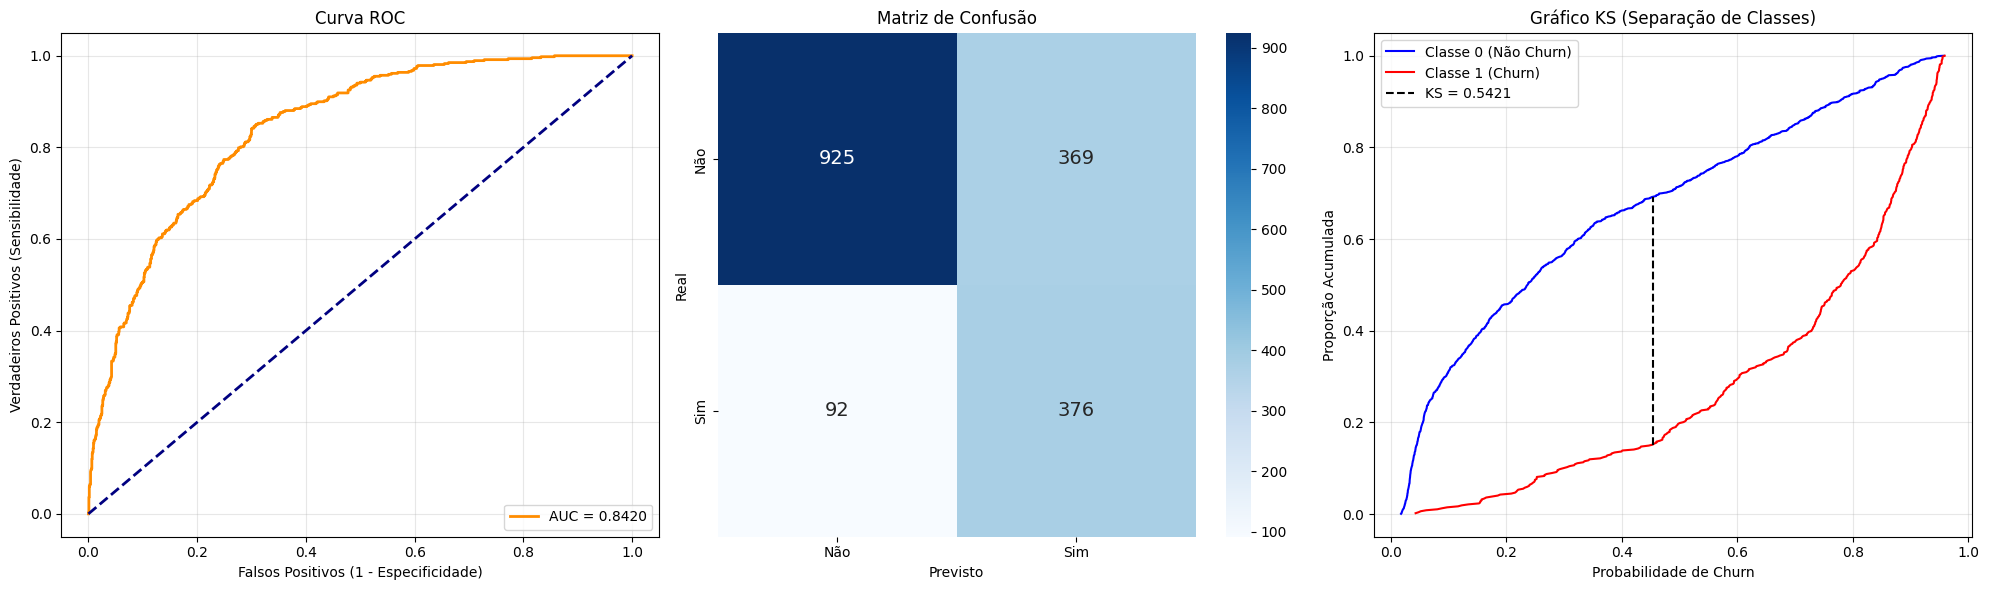


=== Detalhes por Classe (Precision, Recall, F1) ===
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1294
           1       0.50      0.80      0.62       468

    accuracy                           0.74      1762
   macro avg       0.71      0.76      0.71      1762
weighted avg       0.80      0.74      0.75      1762



In [30]:
# ==============================================================================
# RELATÓRIO FINAL: Métricas, KS, ROC e Matriz de Confusão
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.metrics import (
    mean_squared_error, classification_report,
    roc_curve, auc, confusion_matrix, precision_recall_fscore_support
)

# 1. Função para extrair TODAS as métricas (Incluindo KS)
def extrair_metricas_completas(nome_conjunto, X, y, modelo):
    # Previsões
    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]

    # MSE
    mse = mean_squared_error(y, y_prob)

    # Precision, Recall, F1 (Média Ponderada)
    # O "_" ignora o quarto valor que estava dando erro (None)
    prec, rec, f1, _ = precision_recall_fscore_support(y, y_pred, average='weighted', zero_division=0)

    # Support (Total de amostras) calculado manualmente
    supp = len(y)

    # Cálculo do KS (Kolmogorov-Smirnov)
    prob_0 = y_prob[y == 0] # Probabilidades dos que são realmente 0 (Não Churn)
    prob_1 = y_prob[y == 1] # Probabilidades dos que são realmente 1 (Churn)

    if len(prob_0) > 0 and len(prob_1) > 0:
        ks_stat, p_value = ks_2samp(prob_1, prob_0)
    else:
        ks_stat = 0.0

    return {
        "Conjunto": nome_conjunto,
        "MSE": f"{mse:.4f}",
        "KS Statistic": f"{ks_stat:.4f}",
        "Precision": f"{prec:.4f}",
        "Recall": f"{rec:.4f}",
        "F1-Score": f"{f1:.4f}",
        "Support": supp
    }

# 2. Gerar Tabela Comparativa
resultados = []
resultados.append(extrair_metricas_completas("Treinamento", X_train, y_train, final_model))
resultados.append(extrair_metricas_completas("Validação", X_val, y_val, final_model))
resultados.append(extrair_metricas_completas("Teste", X_test, y_test, final_model))

df_resultados = pd.DataFrame(resultados).set_index("Conjunto")

print("=== 📊 TABELA GERAL DE RESULTADOS (Incluindo KS) ===")
display(df_resultados)
print("\nNota sobre KS: Quanto maior (perto de 1.0), melhor o modelo separa Churn de Não-Churn.")
print("-" * 80)

# 3. Geração dos Gráficos (Baseado no Teste)
y_prob_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = final_model.predict(X_test)

# Configurar área de plotagem (3 gráficos lado a lado)
fig, ax = plt.subplots(1, 3, figsize=(20, 6))

# --- GRÁFICO 1: Curva ROC ---
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
roc_auc = auc(fpr, tpr)

ax[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.4f}')
ax[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[0].set_title('Curva ROC')
ax[0].set_xlabel('Falsos Positivos (1 - Especificidade)')
ax[0].set_ylabel('Verdadeiros Positivos (Sensibilidade)')
ax[0].legend(loc="lower right")
ax[0].grid(alpha=0.3)

# --- GRÁFICO 2: Matriz de Confusão ---
cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[1], annot_kws={"size": 14})
ax[1].set_title('Matriz de Confusão')
ax[1].set_xlabel('Previsto')
ax[1].set_ylabel('Real')
ax[1].set_xticklabels(['Não', 'Sim'])
ax[1].set_yticklabels(['Não', 'Sim'])

# --- GRÁFICO 3: Curvas KS (Densidade Acumulada) ---
# Ordenar probabilidades para o gráfico KS
prob_0 = np.sort(y_prob_test[y_test == 0])
prob_1 = np.sort(y_prob_test[y_test == 1])
n0 = len(prob_0)
n1 = len(prob_1)
y0 = np.arange(1, n0 + 1) / n0
y1 = np.arange(1, n1 + 1) / n1

# Plotar as curvas acumuladas
ax[2].plot(prob_0, y0, label='Classe 0 (Não Churn)', color='blue')
ax[2].plot(prob_1, y1, label='Classe 1 (Churn)', color='red')

# Calcular e desenhar a linha do KS (máxima separação)
ks_stat_test = float(df_resultados.loc["Teste", "KS Statistic"])
# Encontrar ponto de máxima distância aproximado para o gráfico
idx_max = np.argmax(np.abs(np.interp(prob_1, prob_0, y0) - y1))
x_max = prob_1[idx_max]
y_max_curve1 = y1[idx_max]
y_max_curve0 = np.interp(x_max, prob_0, y0)

ax[2].vlines(x_max, ymin=min(y_max_curve0, y_max_curve1), ymax=max(y_max_curve0, y_max_curve1),
             color='black', linestyle='--', label=f'KS = {ks_stat_test:.4f}')

ax[2].set_title('Gráfico KS (Separação de Classes)')
ax[2].set_xlabel('Probabilidade de Churn')
ax[2].set_ylabel('Proporção Acumulada')
ax[2].legend()
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Relatório textual detalhado
print("\n=== Detalhes por Classe (Precision, Recall, F1) ===")
print(classification_report(y_test, y_pred_test))

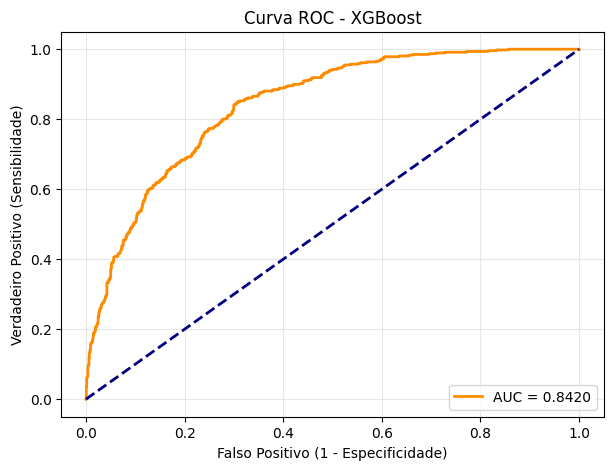

In [31]:
# --- CÉLULA: CURVA ROC ---
from sklearn.metrics import roc_curve, auc

y_prob_test = final_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('Curva ROC - XGBoost')
plt.xlabel('Falso Positivo (1 - Especificidade)')
plt.ylabel('Verdadeiro Positivo (Sensibilidade)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

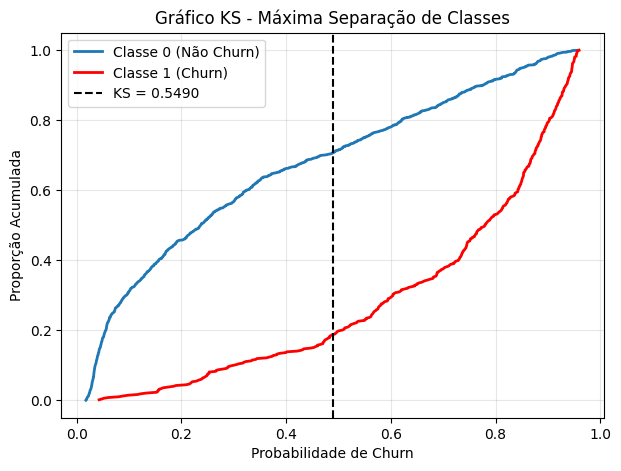

In [32]:
# --- CÉLULA: GRÁFICO KS ---
prob_0 = np.sort(y_prob_test[y_test == 0])
prob_1 = np.sort(y_prob_test[y_test == 1])
cdf_0 = np.arange(1, len(prob_0) + 1) / len(prob_0)
cdf_1 = np.arange(1, len(prob_1) + 1) / len(prob_1)

plt.figure(figsize=(7, 5))
plt.plot(prob_0, cdf_0, label='Classe 0 (Não Churn)', lw=2)
plt.plot(prob_1, cdf_1, label='Classe 1 (Churn)', lw=2, color='red')

# Threshold de máxima separação (baseado no seu resultado de 0.5490)
threshold_ks = 0.49
plt.axvline(threshold_ks, color='black', linestyle='--', label='KS = 0.5490')

plt.title('Gráfico KS - Máxima Separação de Classes')
plt.xlabel('Probabilidade de Churn')
plt.ylabel('Proporção Acumulada')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

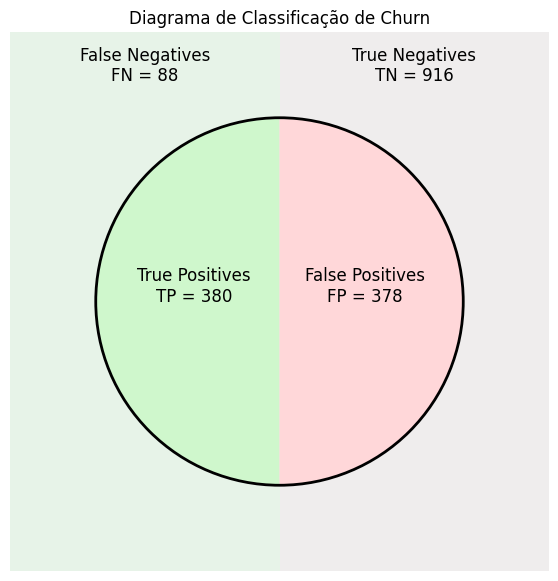

In [33]:
# --- CÉLULA: MATRIZ E DIAGRAMA ---
from matplotlib.patches import Rectangle, Wedge, Circle

threshold_ks = 0.49
y_pred_test = (y_prob_test >= threshold_ks).astype(int)
cm = confusion_matrix(y_test, y_pred_test)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7,7))
ax.set_aspect('equal'); ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.axis('off')

# Desenho do diagrama (mesmo padrão do seu amigo)
ax.add_patch(Rectangle((-1.1, -1.1), 1.1, 2.2, facecolor='#e7f3e8')) # Lado Churn
ax.add_patch(Rectangle((0.0, -1.1), 1.1, 2.2, facecolor='#efeded')) # Lado Não Churn
ax.add_patch(Wedge((0,0), 0.75, 90, 270, facecolor='#cff7cc'))      # TP
ax.add_patch(Wedge((0,0), 0.75, 270, 90, facecolor='#ffd7d9'))      # FP
ax.add_patch(Circle((0,0), 0.75, facecolor='none', edgecolor='black', lw=2))

ax.text(-0.55, 0.9, f"False Negatives\nFN = {fn}", ha='center', fontsize=12)
ax.text(0.55, 0.9, f"True Negatives\nTN = {tn}", ha='center', fontsize=12)
ax.text(-0.35, 0.0, f"True Positives\nTP = {tp}", ha='center', fontsize=12)
ax.text(0.35, 0.0, f"False Positives\nFP = {fp}", ha='center', fontsize=12)
plt.title("Diagrama de Classificação de Churn")
plt.show()

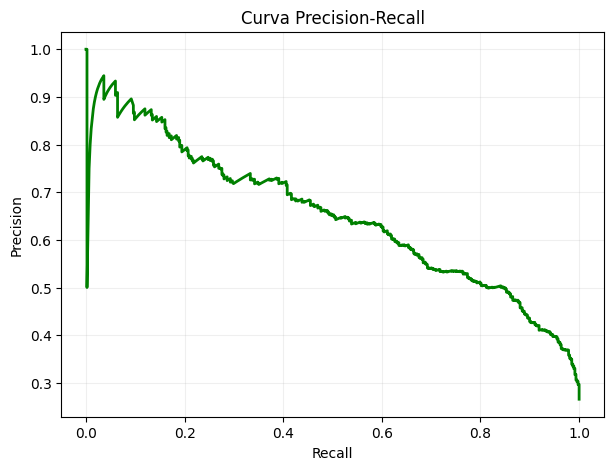

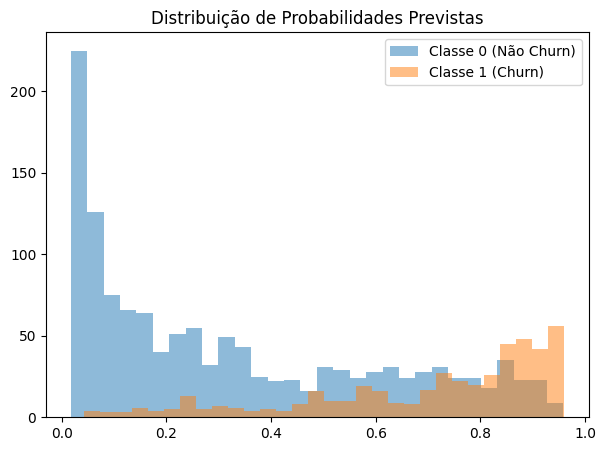

In [34]:
# --- CÉLULA: PRECISION-RECALL E DISTRIBUIÇÃO ---
from sklearn.metrics import precision_recall_curve

prec, rec, _ = precision_recall_curve(y_test, y_prob_test)

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, lw=2, color='green')
plt.title('Curva Precision-Recall')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(y_prob_test[y_test==0], bins=30, alpha=0.5, label='Classe 0 (Não Churn)')
plt.hist(y_prob_test[y_test==1], bins=30, alpha=0.5, label='Classe 1 (Churn)')
plt.title('Distribuição de Probabilidades Previstas')
plt.legend()
plt.show()